# Loan default model: analysis

This notebook predicts whether a loan applicant will default, compares the model with Bree's
rule-based scorer, and checks fairness across employment groups. Reusable code lives in the
`loan_risk/` package; this notebook runs it and explains the results.

**Contents**
1. Data audit: what's in the data, what's missing, and where it differs from the brief
2. Exploratory analysis: which signals predict default, and how
3. The rule-based baseline: how well it ranks risk, what its decisions cost, and whether it is fair
4. Choosing the model: three candidates compared by cross-validation, tuning, features, calibration
5. The model against the baseline: the untouched test set, robustness, and what deployment would change

To re-run: `jupytext --to ipynb analysis.py && jupyter nbconvert --to notebook --execute --inplace analysis.ipynb`

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
from statsmodels.stats.proportion import proportions_ztest

from loan_risk import plots
from loan_risk.baseline import (
    adjusted_rule_score,
    oracle_default_probability,
    rebuild_rule_score,
    rule_components,
    rule_tiers,
    tiers_from_score,
)
from loan_risk.data import EMPLOYMENT_GROUPS, default_label, load_applications, split_by_outcome, train_test_indices
from loan_risk.eda import adversarial_auc, binned_rate, format_rates, rate_table
from loan_risk.evaluation import (
    CONVENTIONS,
    approvals_at_predicted_rate,
    binary_metrics,
    bootstrap_strategy_band,
    confusion_table,
    convention_metrics,
    dollars_approved,
    matched_tiers,
    paired_bootstrap,
    probability_metrics,
    ranking_metrics,
    save_table,
    strategy_curve,
    swap_sets,
    tier_table,
)
from loan_risk.fairness import score_conditional_odds
from loan_risk.features import (
    CANDIDATE_FEATURES,
    EMPLOYMENT_VARIANTS,
    FEATURE_LABELS,
    INCOME_VERIFICATION_LABELS,
    MISMATCH_THRESHOLD,
    VARIANT_DESCRIPTIONS,
    build_features,
    linear_matrix,
    loan_to_income_alternatives,
    tree_matrix,
)
from loan_risk.modeling import (
    ADDITIVE_GBM_PARAMS,
    PRODUCTION_VARIANT,
    cross_validate,
    cv_splits,
    make_additive_gbm,
    make_logistic,
    make_platt_calibrated,
    make_production_model,
    make_unconstrained_gbm,
    one_se_choice,
    reference_folds,
    summarize,
)

plots.apply_style()
pd.set_option("display.precision", 4)
GROUP_LABELS = {"employed": "Employed", "self_employed": "Self-employed", "unemployed": "Unemployed"}

applications = load_applications()
resolved, ongoing = split_by_outcome(applications)
y = default_label(resolved)
features = build_features(resolved)
print(f"{len(applications):,} applications: {len(resolved):,} resolved "
      f"({y.sum()} defaults = {y.mean():.1%}), {len(ongoing)} ongoing")

2,000 applications: 1,836 resolved (545 defaults = 29.7%), 164 ongoing


## 1. Data audit

### 1.1 Columns and missing values

Fifteen columns. Only two have gaps, and both gaps have a known cause (sections 1.3 and 1.5).

In [2]:
audit = pd.DataFrame(
    {
        "type": applications.dtypes.astype(str),
        "missing": applications.isna().sum(),
        "first row": applications.iloc[0].astype(str),
    }
)
display(audit)

,type,missing,first row
applicant_id,str,0,APP-0000
stated_monthly_income,float64,0,3683.0
documented_monthly_income,float64,283,3462.0
loan_amount,int64,0,2000
employment_status,str,0,employed
bank_ending_balance,float64,0,3084.0
bank_has_overdrafts,bool,0,False
bank_has_consistent_deposits,bool,0,True
monthly_withdrawals,float64,0,1927.0
monthly_deposits,float64,0,3337.0


### 1.2 What the brief says vs what the data shows

I checked each data characteristic the brief lists against the generated file.

In [3]:
outcome_share = applications["actual_outcome"].value_counts(normalize=True)
doc_ratio = applications["documented_monthly_income"] / applications["stated_monthly_income"]
stated_multiple = 1 / doc_ratio
mismatch = doc_ratio < MISMATCH_THRESHOLD
three_x = int((stated_multiple >= 3).sum())
employment_share = applications["employment_status"].value_counts(normalize=True)
employment_rates = rate_table(y, resolved["employment_status"], EMPLOYMENT_GROUPS)
_, p_self = proportions_ztest(
    employment_rates.loc[["self_employed", "employed"], "defaults"],
    employment_rates.loc[["self_employed", "employed"], "n"],
)

brief_check = pd.DataFrame(
    [
        ("Outcomes: repaid / defaulted / ongoing", "~78% / ~14% / ~8%",
         " / ".join(f"{outcome_share[o]:.1%}" for o in ["repaid", "defaulted", "ongoing"]),
         "No: about twice as many defaults"),
        ("Documented income missing", "~15%",
         f"{applications['documented_monthly_income'].isna().mean():.1%}", "Yes"),
        ("Misrepresentation (stated income 3x+ documented)", "~5% of rows",
         f"{mismatch.sum()} clear mismatches ({mismatch.mean():.1%}); only {three_x} are 3x+",
         f"Partly: a 3x cutoff misses {mismatch.sum() - three_x} of {mismatch.sum()}"),
        ("Employment: employed / self-employed / unemployed", "three values",
         " / ".join(f"{employment_share[g]:.0%}" for g in EMPLOYMENT_GROUPS), "Yes"),
        ("Self-employed default about as often as employed", "roughly the same",
         f"{employment_rates.loc['self_employed', 'rate']:.1%} vs "
         f"{employment_rates.loc['employed', 'rate']:.1%} (p = {p_self:.2f})", "Yes"),
    ],
    columns=["Claim", "Brief", "Data", "Holds?"],
).set_index("Claim")
display(brief_check)

,Brief,Data,Holds?
Claim,,,
Outcomes: repaid / defaulted / ongoing,~78% / ~14% / ~8%,64.5% / 27.3% / 8.2%,No: about twice as many defaults
Documented income missing,~15%,14.1%,Yes
Misrepresentation (stated income 3x+ documented),~5% of rows,85 clear mismatches (4.2%); only 56 are 3x+,Partly: a 3x cutoff misses 29 of 85
Employment: employed / self-employed / unemployed,three values,59% / 31% / 10%,Yes
Self-employed default about as often as employed,roughly the same,29.0% vs 27.2% (p = 0.45),Yes


**Two discrepancies matter for modeling.**
- **The default rate is about double what the brief says**: 27% of all applications, 30% of
  resolved ones. The classes are only mildly imbalanced, so there's no case for resampling.
- **The brief's "3x+" description of misrepresentation is too narrow.** Mismatches are better
  found by the empty gap in documented ÷ stated income (section 2.1); a 3x cutoff would miss a
  third of them.

### 1.3 Missing documented income is structural, not random

In [4]:
display(pd.crosstab(
    applications["num_documents_submitted"],
    applications["documented_monthly_income"].isna().map({True: "missing", False: "present"}),
    margins=True,
))

documented_monthly_income,missing,present,All
num_documents_submitted,,,
0,283,0,283
1,0,683,683
2,0,1034,1034
All,283,1717,2000


Documented income is missing **exactly** when an applicant submitted no documents (283 people).
So the gap is a signal in its own right: these applicants default far more often (section 2.1).
Filling in a typical income (mean or median imputation) would invent a verified income and erase
that signal, so the model gets an explicit "not provided" category instead.

### 1.4 Floors and value sets

In [5]:
at_floor = applications["stated_monthly_income"] == 500
print(f"Stated income at exactly $500 (the generator's floor): {at_floor.sum()} applicants, "
      f"{applications.loc[at_floor, 'employment_status'].eq('unemployed').mean():.0%} of them unemployed")
print(f"Bank balance at exactly $0 (floor): {(applications['bank_ending_balance'] == 0).sum()} applicants")
print(f"Loan amounts take {applications['loan_amount'].nunique()} values: "
      f"{sorted(applications['loan_amount'].unique().tolist())}")

Stated income at exactly $500 (the generator's floor): 41 applicants, 66% of them unemployed
Bank balance at exactly $0 (floor): 176 applicants
Loan amounts take 7 values: [300, 500, 1000, 1500, 2000, 3000, 5000]


Both floors are where the generator clipped values, so the true figure below them is unknown (a
$0 balance may hide an overdrawn account). Tree-based models handle this without special care.
Loan amounts come from a menu of seven sizes, so loan ÷ income varies mostly through income.

### 1.5 `days_to_default` leaks the outcome

In [6]:
defaulted = applications[applications["actual_outcome"] == "defaulted"]
defaulted_features = build_features(defaulted)
print(f"days_to_default is filled in for {applications['days_to_default'].notna().sum()} rows, all of them "
      f"defaults; range {defaulted['days_to_default'].min():.0f}-{defaulted['days_to_default'].max():.0f} days")
candidates = {
    "loan / income": defaulted_features["loan_to_income"],
    "withdrawals / deposits": defaulted_features["withdrawal_to_deposit"],
    "bank balance": defaulted["bank_ending_balance"],
    "rule-based score": defaulted["rule_based_score"],
}
display(pd.DataFrame({
    "Spearman correlation with days_to_default": {
        name: stats.spearmanr(values, defaulted["days_to_default"]).statistic for name, values in candidates.items()
    }
}).round(3))

days_to_default is filled in for 545 rows, all of them defaults; range 15-179 days


,Spearman correlation with days_to_default
loan / income,-0.072
withdrawals / deposits,-0.045
bank balance,-0.003
rule-based score,-0.048


It only exists after a loan has defaulted, so as a feature it would hand the model the answer: it is
excluded. It also shows no pattern (spread evenly over 15-179 days and unrelated to any feature), so
there's nothing to learn about *when* defaults happen. One fact is still useful: **every default
happens by day 179**, which matters for the ongoing loans below.

### 1.6 Ongoing loans look like everyone else

In [7]:
all_features = build_features(applications)
is_ongoing = applications["actual_outcome"].eq("ongoing")
profile = pd.DataFrame(
    {
        "stated monthly income ($)": applications["stated_monthly_income"],
        "loan amount ($)": applications["loan_amount"],
        "loan / income": all_features["loan_to_income"],
        "bank balance ($)": applications["bank_ending_balance"],
        "has overdrafts (share)": applications["bank_has_overdrafts"].astype(float),
        "no income documents (share)": applications["documented_monthly_income"].isna().astype(float),
        "unemployed (share)": all_features["unemployed"].astype(float),
        "rule-based score": applications["rule_based_score"],
    }
)
ongoing_vs_resolved = profile.groupby(is_ongoing.map({False: "resolved", True: "ongoing"})).mean().T[["resolved", "ongoing"]]
ongoing_vs_resolved["p-value (Mann-Whitney)"] = [
    stats.mannwhitneyu(profile.loc[is_ongoing, c], profile.loc[~is_ongoing, c]).pvalue for c in profile.columns
]
display(ongoing_vs_resolved.round(3))
for name, auc in adversarial_auc(all_features, is_ongoing).items():
    print(f"Can {name} tell ongoing loans from resolved ones? Cross-validated AUC = {auc:.2f} (0.5 = chance)")

actual_outcome,resolved,ongoing,p-value (Mann-Whitney)
stated monthly income ($),4439.577,4693.195,0.100
loan amount ($),1554.956,1543.293,0.935
loan / income,0.508,0.415,0.345
bank balance ($),2113.682,2008.866,0.290
has overdrafts (share),0.163,0.213,0.096
no income documents (share),0.141,0.152,0.675
unemployed (share),0.099,0.091,0.752
rule-based score,69.203,69.127,0.844


Can logistic regression tell ongoing loans from resolved ones? Cross-validated AUC = 0.52 (0.5 = chance)
Can gradient boosting tell ongoing loans from resolved ones? Cross-validated AUC = 0.43 (0.5 = chance)


The averages differ a little (for example, 21% vs 16% have overdrafts), but no difference is
statistically significant for a group of 164, and neither classifier can tell the groups apart.
With no real signal, cross-validated AUC scatters around 0.5 and can land below it, as it does for
gradient boosting here. In this dataset "ongoing" was assigned at random, so **leaving these 164
loans out of training introduces no bias here.**

In a real lending book it would. Ongoing loans are the newest ones, and among new loans the fast
defaulters are already labeled while slow outcomes are not. Dropping them over-weights early
defaults and older loans. The production fix is a fixed performance window: label a loan only once
it is 180 days old, since no default here happens after day 179. The alternatives are worse:
calling ongoing loans "repaid" would mislabel the roughly 30% that will default, and a survival
model needs each loan's time on book, which the data doesn't record. The final model scores these
164 loans at the end.

## 2. Exploratory analysis

### 2.1 Income verification: a clean gap, and the strongest single signal

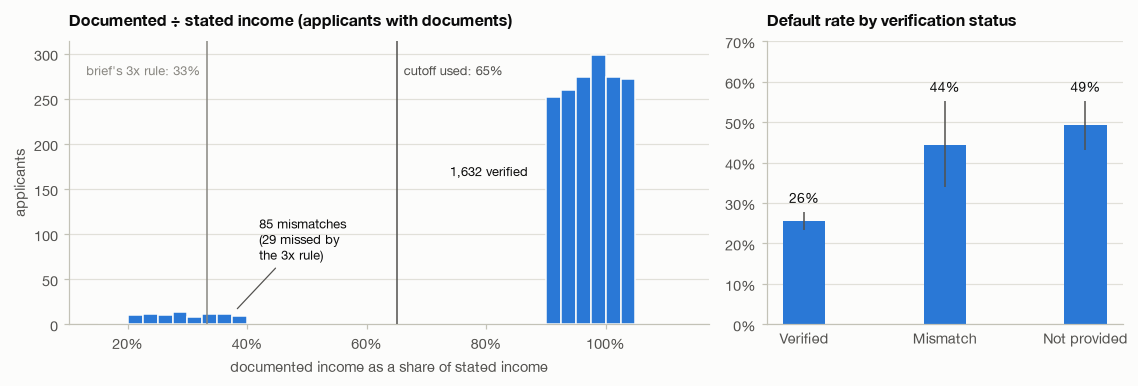

,n,defaults,rate (%),ci_low (%),ci_high (%)
verified,1499,383,25.6,23.4,27.8
mismatch,79,35,44.3,33.9,55.3
not provided,258,127,49.2,43.2,55.3


In [8]:
ratio = doc_ratio.dropna()
status = features["income_verification"].map(INCOME_VERIFICATION_LABELS)
verification_rates = rate_table(y, status, ["verified", "mismatch", "not provided"])
n_mismatch = int((ratio < MISMATCH_THRESHOLD).sum())
missed_by_3x = int(((ratio > 1 / 3) & (ratio < MISMATCH_THRESHOLD)).sum())

fig, (ax_hist, ax_rate) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.8, 1]})
counts, _, _ = ax_hist.hist(ratio, bins=np.arange(0.15, 1.1251, 0.025), color=plots.BLUE,
                            edgecolor=plots.SURFACE, linewidth=1, zorder=2)
top = counts.max()
ax_hist.axvline(MISMATCH_THRESHOLD, color=plots.INK_SECONDARY, linewidth=1, zorder=3)
ax_hist.axvline(1 / 3, color=plots.MUTED, linewidth=1, zorder=3)
ax_hist.text(MISMATCH_THRESHOLD + 0.012, top * 0.97, "cutoff used: 65%", color=plots.INK_SECONDARY,
             fontsize=8.5, va="top")
ax_hist.text(1 / 3 - 0.012, top * 0.97, "brief's 3x rule: 33%", color=plots.MUTED, fontsize=8.5,
             va="top", ha="right")
ax_hist.annotate(f"{n_mismatch} mismatches\n({missed_by_3x} missed by\nthe 3x rule)", xy=(0.38, top * 0.05),
                 xytext=(0.42, top * 0.24), fontsize=8.5, color=plots.INK, ha="left",
                 arrowprops={"arrowstyle": "-", "color": plots.INK_SECONDARY, "linewidth": 0.8})
ax_hist.text(0.87, top * 0.55, f"{len(ratio) - n_mismatch:,} verified", ha="right", fontsize=8.5, color=plots.INK)
ax_hist.set_title("Documented ÷ stated income (applicants with documents)")
ax_hist.set_xlabel("documented income as a share of stated income")
ax_hist.set_ylabel("applicants")
plots.percent_axis(ax_hist, "x")
plots.rate_bars(ax_rate, verification_rates, labels=["Verified", "Mismatch", "Not provided"])
ax_rate.set_title("Default rate by verification status")
ax_rate.set_ylim(0, 0.7)
fig.tight_layout()
plots.save(fig, "fig1_income_verification")
plt.show()
display(format_rates(verification_rates))

Documented income either matches stated income (90-105%) or falls far below it (21-40%), with
nothing in between. So any cutoff inside the gap gives the same split; I use 65%. The brief's "3x"
description would miss the 29 mismatches between 33% and 40%.

Applicants whose income can't be verified default far more often: 44% with a mismatch and 49% with
no documents, against 26% when income is verified. The two failure modes behave alike, which is why
they share one feature with three levels rather than an imputed income.

### 2.2 Risk jumps in steps

Each panel splits applicants into ten equal-sized groups by one feature (no hand-picked cutoffs) and
shows each group's default rate. The shaded band is the 95% confidence interval; the gray line is
the overall default rate.

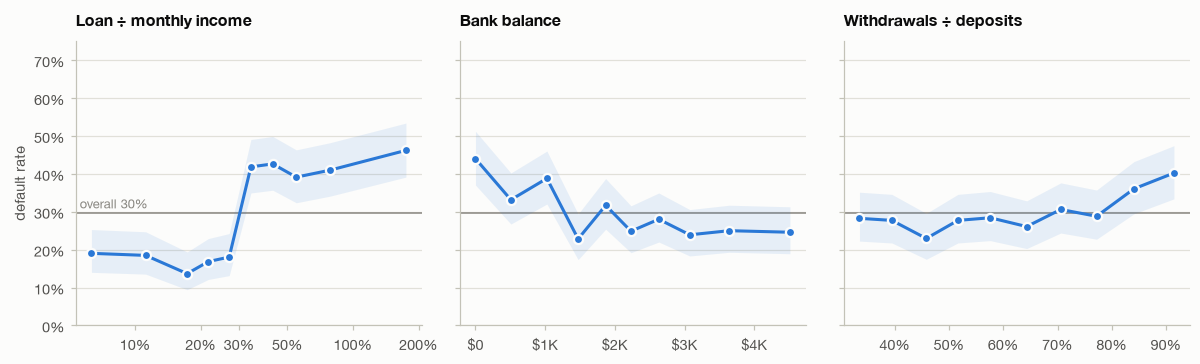

x_low    x_high    n  rate (%)  ci_low (%)  \
Loan ÷ monthly income  0     0.035     0.083  184      19.0        14.0   
                       1     0.083     0.146  184      18.5        13.5   
                       2     0.146     0.194  183      13.7         9.4   
                       3     0.194     0.241  184      16.8        12.1   
                       4     0.241     0.299  183      18.0        13.1   
                       5     0.300     0.379  184      41.8        35.0   
                       6     0.379     0.474  183      42.6        35.7   
                       7     0.475     0.645  184      39.1        32.4   
                       8     0.646     1.003  183      41.0        34.1   
                       9     1.003    10.000  184      46.2        39.1   
Bank balance           0     0.000   144.000  184      44.0        37.0   
                       1   147.000   775.000  184      33.2        26.8   
                       2   776.000  1234.000  183      38.8        32.0   
                       3  1239.000  1677.000  184      22.8        17.4   
                       4  1679.000  2052.000  183      31.7        25.4   
                       5  2054.000  2416.000  185      24.9        19.2   
                       6  2417.000  2866.000  182      28.0        22.0   
                       7  2869.000  3341.000  184      23.9        18.3   
                       8  3348.000  4038.000  184      25.0        19.3   
                       9  4040.000  8719.000  183      24.6        18.9   
Withdrawals ÷ deposits 0     0.300     0.366  184      28.3        22.3   
                       1     0.367     0.429  184      27.7        21.8   
                       2     0.429     0.487  183      23.0        17.5   
                       3     0.489     0.545  184      27.7        21.8   
                       4     0.545     0.609  183      28.4        22.4   
                       5     0.610     0.677  184      26.1        20.3   
                       6     0.677     0.734  183      30.6        24.4   
                       7     0.734     0.807  184      28.8        22.7   
                       8     0.808     0.877  183      36.1        29.5   
                       9     0.878     0.950  184      40.2        33.4   

                          ci_high (%)  
Loan ÷ monthly income  0         25.3  
                       1         24.7  
                       2         19.4  
                       3         22.9  
                       4         24.2  
                       5         49.1  
                       6         49.9  
                       7         46.3  
                       8         48.2  
                       9         53.4  
Bank balance           0         51.2  
                       1         40.2  
                       2         46.0  
                       3         29.4  
                       4         38.8  
                       5         31.6  
                       6         34.9  
                       7         30.6  
                       8         31.7  
                       9         31.3  
Withdrawals ÷ deposits 0         35.2  
                       1         34.6  
                       2         29.6  
                       3         34.6  
                       4         35.3  
                       5         32.9  
                       6         37.6  
                       7         35.7  
                       8         43.2  
                       9         47.4

In [9]:
drivers = {
    "loan_to_income": "Loan ÷ monthly income",
    "bank_ending_balance": "Bank balance",
    "withdrawal_to_deposit": "Withdrawals ÷ deposits",
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
binned = {}
for ax, (column, title) in zip(axes, drivers.items()):
    table = binned_rate(features[column], y, n_bins=10)
    binned[title] = table
    ax.axhline(y.mean(), color=plots.MUTED, linewidth=1, zorder=1)
    plots.rate_line(ax, table)
    ax.set_title(title)
axes[0].set_xscale("log")
axes[0].set_xticks([0.1, 0.2, 0.3, 0.5, 1, 2], ["10%", "20%", "30%", "50%", "100%", "200%"])
axes[0].minorticks_off()
plots.dollar_axis(axes[1])
plots.percent_axis(axes[2], "x")
axes[0].set_ylabel("default rate")
axes[0].set_ylim(0, 0.75)
axes[0].text(axes[0].get_xlim()[0], y.mean() + 0.012, f" overall {y.mean():.0%}", color=plots.MUTED, fontsize=8.5)
fig.tight_layout()
plots.save(fig, "fig2_risk_steps")
plt.show()
display(pd.concat({
    title: format_rates(table[["x_low", "x_high", "n", "rate", "ci_low", "ci_high"]]) for title, table in binned.items()
}).round(3))

- **Loan ÷ income** has a sharp step: 14-19% default below 30% of monthly income, 39-46% above it,
  and little change after that.
- **Bank balance** matters mostly at the low end: 44% default in the lowest tenth (under about $150)
  and 33-39% up to about $1,200, against roughly 25% above. This pattern is noisier.
- **Withdrawals ÷ deposits** is flat until about 80%, then rises to 36-40%.

A straight-line (linear) term gets step shapes like these wrong. Tree-based models learn them
directly from the data, without anyone choosing the cutoffs by hand.

### 2.3 Yes/no signals, and two columns that carry no signal

In [10]:
def yes_no(series: pd.Series) -> pd.Series:
    return series.map({True: "yes", False: "no"})


binary_rates = pd.concat({
    "Has overdrafts": rate_table(y, yes_no(resolved["bank_has_overdrafts"]), ["no", "yes"]),
    "Documents submitted": rate_table(y, resolved["num_documents_submitted"].astype(str), ["0", "1", "2"]),
    "Consistent deposits": rate_table(y, yes_no(resolved["bank_has_consistent_deposits"]), ["no", "yes"]),
})
display(format_rates(binary_rates))

with_label = resolved.assign(defaulted=y)
consistent = with_label["bank_has_consistent_deposits"]
proxy = pd.DataFrame({
    "share with consistent deposits": with_label.groupby("employment_status")["bank_has_consistent_deposits"].mean(),
    "default rate if consistent": with_label[consistent].groupby("employment_status")["defaulted"].mean(),
    "default rate if not": with_label[~consistent].groupby("employment_status")["defaulted"].mean(),
}).reindex(EMPLOYMENT_GROUPS)
display((100 * proxy).round(1).rename(index=GROUP_LABELS).add_suffix(" (%)"))

n  defaults  rate (%)  ci_low (%)  ci_high (%)
Has overdrafts      no   1537       400      26.0        23.9         28.3
                    yes   299       145      48.5        42.9         54.1
Documents submitted 0     258       127      49.2        43.2         55.3
                    1     637       159      25.0        21.8         28.5
                    2     941       259      27.5        24.8         30.5
Consistent deposits no    642       194      30.2        26.8         33.9
                    yes  1194       351      29.4        26.9         32.0

,share with consistent deposits (%),default rate if consistent (%),default rate if not (%)
employment_status,,,
Employed,82.2,28.3,22.2
Self-employed,41.5,28.5,29.3
Unemployed,35.7,47.7,46.2


**Overdrafts** nearly double the default rate (26% to 49%). Two columns carry no signal:
- **Number of documents** matters only as zero versus any: one and two documents default at 25%
  and 28%.
- **Deposit consistency** makes no meaningful difference, overall (30% vs 29%) or within any
  employment group. Yet it tracks employment closely: 82% of employed applicants have consistent
  deposits, against 42% of self-employed and 36% of unemployed. A model using it would learn
  nothing about risk but could penalize self-employment indirectly, so it is left out and
  revisited in the fairness analysis.

### 2.4 Employment: similar risk, very different treatment

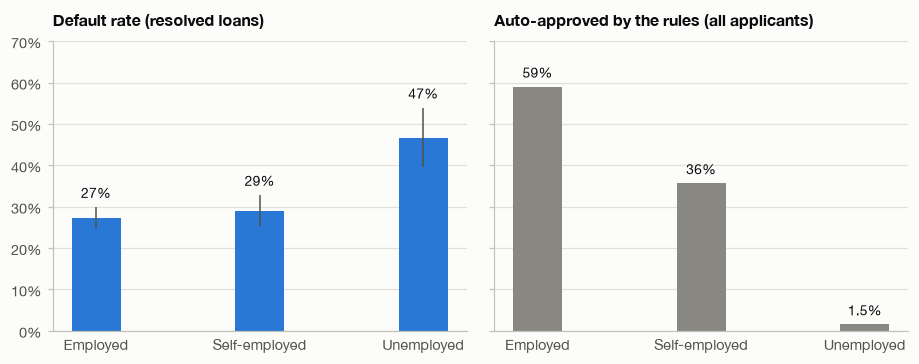

,n,defaults,rate (%),ci_low (%),ci_high (%),rules: approved (%),rules: denied (%),rules: flagged_for_review (%)
Employed,1088,296,27.2,24.6,29.9,59.0,6.8,34.2
Self-employed,566,164,29.0,25.4,32.8,35.6,16.9,47.4
Unemployed,182,85,46.7,39.6,53.9,1.5,46.7,51.8


Approval ratio, self-employed vs employed: 0.60 (below 0.8 is the usual warning line)


In [11]:
decision_mix = pd.crosstab(
    applications["employment_status"], applications["rule_based_decision"], normalize="index"
).reindex(EMPLOYMENT_GROUPS)
labels = [GROUP_LABELS[g] for g in EMPLOYMENT_GROUPS]
fig, (ax_default, ax_approve) = plt.subplots(1, 2, figsize=(8.5, 3.4), sharey=True)
plots.rate_bars(ax_default, employment_rates, labels)
ax_default.set_title("Default rate (resolved loans)")
plots.rate_bars(ax_approve, decision_mix[["approved"]].rename(columns={"approved": "rate"}), labels,
                color=plots.RULES_COLOR)
ax_approve.set_title("Auto-approved by the rules (all applicants)")
ax_default.set_ylim(0, 0.7)
fig.tight_layout()
plots.save(fig, "fig3_employment")
plt.show()

summary = format_rates(employment_rates).join((100 * decision_mix).round(1).add_prefix("rules: ").add_suffix(" (%)"))
display(summary.rename(index=GROUP_LABELS))
ratio_self = decision_mix.loc["self_employed", "approved"] / decision_mix.loc["employed", "approved"]
print(f"Approval ratio, self-employed vs employed: {ratio_self:.2f} (below 0.8 is the usual warning line)")

Self-employed applicants default about as often as employed ones (29% vs 27%; not a significant
difference, p = 0.45). Yet the rules auto-approve them far less often: 36% vs 59%, an approval
ratio of 0.60, well below the 0.8 warning line used in fair-lending checks. Unemployed applicants
really are riskier (47%) and are almost never auto-approved (1.5%). Whether the rule score actually
mis-prices these groups, once the other risk factors are accounted for, is tested when the
baseline is evaluated.

### 2.5 What this means for the model

- **Label and exclusions.** Predict defaulted (1) vs repaid (0) on the 1,836 resolved loans. Leave out
  `days_to_default` (it leaks the outcome), the rule-based score and decision (outputs of the system
  being replaced) and `applicant_id`.
- **Missing documents and mismatches become one feature**, `income_verification` (verified /
  mismatch / not provided), instead of an imputed income.
- **Use a model that can learn steps.** Risk jumps at thresholds (section 2.2), so a straight-line
  effect would mis-fit; trees find the thresholds in the data.
- **Drop columns with no signal**: deposit consistency (also an employment proxy) and the document
  count beyond zero.
- **No resampling.** A 30% default rate is only mildly imbalanced, and resampling would distort the
  predicted probabilities. Decision thresholds handle the business costs instead.

## 3. The rule-based baseline

The rules combine five factors into a 0-100 score, then approve at 75 or above, flag for human
review at 50-74 and deny below 50. This section measures how well that works and where it goes
wrong. The rules need no training, so they are evaluated on all 1,836 resolved loans.

### 3.1 How the score really behaves

In [12]:
rebuilt = rebuild_rule_score(applications)
gap = (rebuilt - applications["rule_based_score"]).abs().round(2)
print(f"Rebuilt rubric: same decision for {(tiers_from_score(rebuilt) == rule_tiers(applications)).sum():,} of "
      f"{len(applications):,} applicants. Score identical for {(gap == 0).sum():,}, 0.1 apart for {(gap == 0.1).sum()}, "
      f"further apart for {(gap > 0.1).sum()} (all from rounding in the CSV)")
components = rule_components(applications)
print("Income-verification points awarded:", components["income_verification"].value_counts().to_dict())
no_docs = applications["documented_monthly_income"].isna()
print(f"Highest score of any applicant without documents: {applications.loc[no_docs, 'rule_based_score'].max():.1f} "
      "(auto-approval needs 75)")

Rebuilt rubric: same decision for 2,000 of 2,000 applicants. Score identical for 1,979, 0.1 apart for 20, further apart for 1 (all from rounding in the CSV)
Income-verification points awarded: {95: 1631, 0: 368, 40: 1}
Highest score of any applicant without documents: 64.5 (auto-approval needs 75)


Rebuilding the rubric from the CSV reproduces all 2,000 decisions, so the baseline is understood
exactly. Two quirks stand out:
- **Income verification is effectively all-or-nothing**: 95 points when documents match, 0
  otherwise. The 40-point "partial match" branch fires for one applicant, and only because the CSV
  rounds documented income.
- **Applicants without documents can never be auto-approved**: missing those 28.5 weighted points
  caps their score at 64.5. That fits the data (they default at 49%), but it comes from the weights
  rather than from an explicit policy.

### 3.2 How well the rules rank risk

In [13]:
rule_risk = -resolved["rule_based_score"].to_numpy()
oracle_p = oracle_default_probability(resolved)
ranking = pd.DataFrame.from_dict(
    {
        "Rule-based score": ranking_metrics(y, rule_risk),
        "Oracle: true default probability (diagnostic only)": ranking_metrics(y, oracle_p),
    },
    orient="index",
)
display(ranking.round(3))
save_table(ranking, "baseline_ranking")
no_risk_factors = oracle_p == oracle_p.min()
print(f"Most any model could add over the rules: {ranking['ROC-AUC'].iloc[1] - ranking['ROC-AUC'].iloc[0]:.3f} AUC")
print(f"Applicants with none of the generator's risk factors: {no_risk_factors.sum()}, "
      f"and {y[no_risk_factors].mean():.0%} of them still default")

,ROC-AUC,PR-AUC
Rule-based score,0.706,0.502
Oracle: true default probability (diagnostic only),0.741,0.525


Most any model could add over the rules: 0.035 AUC
Applicants with none of the generator's risk factors: 459, and 9% of them still default


**AUC** is the probability that a randomly chosen defaulter gets a riskier score than a randomly
chosen repayer: 0.5 is a coin flip, 1.0 is perfect. **PR-AUC** (average precision) measures how
cleanly the riskiest scores pick out defaulters; a random score gets about 0.30 here, the default
rate. The rules reach **0.706 AUC**.

Because the brief includes the generator, I can compute each applicant's true default probability:
the "oracle". It is never used to train, tune or select anything; it only shows the ceiling, **0.741
AUC**. Outcomes are noisy by design: 459 applicants with none of the risk factors still default 9% of
the time. So **the most any model can add over the rules is about 0.035 AUC**, and models should be
judged against that ceiling rather than a perfect 1.0.

### 3.3 What the decisions cost

In [14]:
rule_decisions = rule_tiers(resolved)
decision_table = tier_table(y, rule_decisions)
display(decision_table.round(3))
rule_metrics = convention_metrics(y, rule_decisions)
display(rule_metrics.round(3))
for name, flagged in CONVENTIONS.items():
    print(f"Confusion matrix, convention {name}")
    display(confusion_table(y, np.isin(rule_decisions, flagged)))
save_table(decision_table, "baseline_tiers")
save_table(rule_metrics, "baseline_conventions")

,applicants,share of applicants,repaid,defaulted,default rate
approve,851,0.464,710,141,0.166
review,720,0.392,459,261,0.362
deny,265,0.144,122,143,0.540


,TP,FP,FN,TN,precision,recall,F1,FPR,FNR
A: only deny = predicted default,143,122,402,1169,0.54,0.262,0.353,0.095,0.738
B: not auto-approved = predicted default,404,581,141,710,0.41,0.741,0.528,0.450,0.259


Confusion matrix, convention A: only deny = predicted default


,predicted repay,predicted default
actual,,
repaid,1169,122
defaulted,402,143


Confusion matrix, convention B: not auto-approved = predicted default


,predicted repay,predicted default
actual,,
repaid,710,581
defaulted,141,404


- Auto-approved applicants default at 17% and denied ones at 54%. The **review tier holds 39% of
  applicants with a 36% default rate, close to the 30% average**: the rules hand their hardest cases
  to people.
- Precision, recall, F1 and error rates need a yes/no prediction, but reviewers' decisions on
  flagged applications aren't in the data. So I report two conventions that bracket the truth:
  - **A** counts only "deny" as predicting default, as if reviewers approved every flagged case. Its
    false-positive rate is the share of good applicants wrongly denied: **9.5%**. But 74% of
    defaults are not denied.
  - **B** counts anything not auto-approved as predicting default, as if reviewers denied every
    flagged case. Its false-negative rate is the share of defaults that slip through
    auto-approval: **26%**. But 45% of good applicants are held back.
- The model is compared under both conventions later.

### 3.4 Does the score mis-price employment groups?

A fair score means the same risk for everyone with the same score. The test fits
logit(default) ~ score + employment group. If group still predicts default once the score is known,
the score mis-prices that group. An odds ratio below 1 means the group defaults less often than its
score implies, so the score over-states its risk.

,odds ratio,ci_low,ci_high,p-value
Self-employed,0.667,0.519,0.857,0.002
Unemployed,0.754,0.521,1.090,0.133


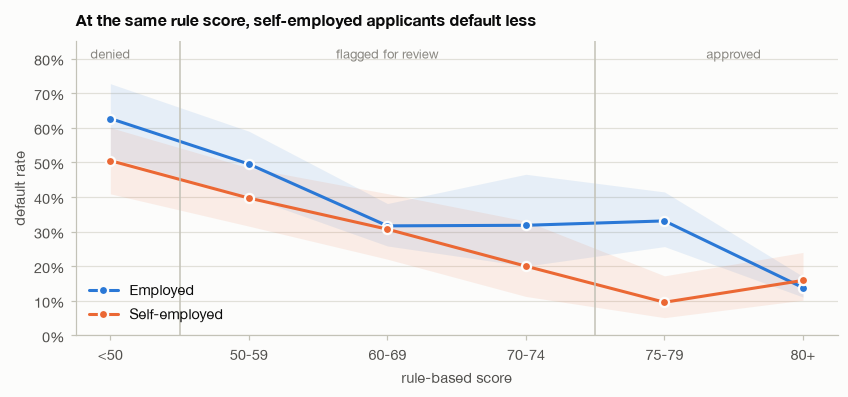

Employed                                 Self-employed           \
             n rate (%) ci_low (%) ci_high (%)             n rate (%)   
<50         75     62.7       51.4        72.7           101     50.5   
50-59      103     49.5       40.1        59.0           126     39.7   
60-69      218     31.7       25.8        38.1            88     30.7   
70-74       44     31.8       20.0        46.6            50     20.0   
75-79      133     33.1       25.7        41.5            94      9.6   
80+        515     13.8       11.1        17.0           107     15.9   

                              
      ci_low (%) ci_high (%)  
<50         40.9        60.0  
50-59       31.6        48.4  
60-69       22.0        41.0  
70-74       11.2        33.0  
75-79        5.1        17.2  
80+         10.2        24.0

In [15]:
score_bias = score_conditional_odds(
    y, resolved["rule_based_score"] / 10, resolved["employment_status"], order=EMPLOYMENT_GROUPS
)
display(score_bias.rename(index=GROUP_LABELS).round(3))
save_table(score_bias, "baseline_score_bias")

band_labels = ["<50", "50-59", "60-69", "70-74", "75-79", "80+"]
bands = pd.cut(resolved["rule_based_score"], [0, 50, 60, 70, 75, 80, 101], right=False,
               labels=band_labels).astype(str).to_numpy()
fig, ax = plt.subplots(figsize=(7.8, 3.7))
x = np.arange(len(band_labels))
band_rates = {}
for group, color in [("employed", plots.BLUE), ("self_employed", plots.ORANGE)]:
    in_group = resolved["employment_status"].eq(group).to_numpy()
    table = rate_table(y[in_group], bands[in_group], band_labels)
    band_rates[GROUP_LABELS[group]] = table
    ax.fill_between(x, table["ci_low"], table["ci_high"], color=color, alpha=0.10, linewidth=0)
    ax.plot(x, table["rate"], color=color, marker="o", markersize=6, markeredgecolor=plots.SURFACE,
            markeredgewidth=1.5, label=GROUP_LABELS[group])
for boundary in (0.5, 3.5):
    ax.axvline(boundary, color=plots.AXIS, linewidth=1)
for center, zone in [(0, "denied"), (2, "flagged for review"), (4.5, "approved")]:
    ax.text(center, 0.80, zone, ha="center", color=plots.MUTED, fontsize=8.5)
ax.set_xticks(x, band_labels)
ax.set_xlabel("rule-based score")
ax.set_ylabel("default rate")
ax.set_ylim(0, 0.85)
plots.percent_axis(ax)
ax.legend(loc="lower left")
ax.set_title("At the same rule score, self-employed applicants default less")
fig.tight_layout()
plots.save(fig, "fig4_rule_score_bias")
plt.show()
display(pd.concat({g: format_rates(t[["n", "rate", "ci_low", "ci_high"]]) for g, t in band_rates.items()}, axis=1))

In [16]:
score = resolved["rule_based_score"]
self_marginal = (resolved["employment_status"].eq("self_employed") & score.between(69, 74.95)).to_numpy()
employed_marginal = (resolved["employment_status"].eq("employed") & score.between(75, 80.95)).to_numpy()
counts_2x2 = [[y[m].sum(), (1 - y[m]).sum()] for m in (self_marginal, employed_marginal)]
print(f"Self-employed scoring 69-74.9 (approved if their 6-point penalty were removed): "
      f"{y[self_marginal].mean():.0%} default (n = {self_marginal.sum()})")
print(f"Employed scoring 75-80.9 (approved today): {y[employed_marginal].mean():.0%} default "
      f"(n = {employed_marginal.sum()}); Fisher exact test p = {stats.fisher_exact(counts_2x2).pvalue:.2f}")
partial_credit = rule_components(resolved)["income_level"].eq(45).to_numpy()
employed_75 = (resolved["employment_status"].eq("employed") & score.between(75, 79.95)).to_numpy()
print(f"Employed applicants scoring 75-79.9: {employed_75.sum()}. {partial_credit[employed_75].mean():.0%} of them "
      f"got partial credit for income only 2-3x the loan; those default at {y[employed_75 & partial_credit].mean():.0%}")

Self-employed scoring 69-74.9 (approved if their 6-point penalty were removed): 23% default (n = 60)
Employed scoring 75-80.9 (approved today): 34% default (n = 166); Fisher exact test p = 0.15
Employed applicants scoring 75-79.9: 133. 71% of them got partial credit for income only 2-3x the loan; those default at 35%


**The score over-states self-employed applicants' risk.** At the same score they are about a third
less likely to default (odds ratio 0.67, 95% CI 0.52-0.86, p = 0.002). The chart shows it band by
band, most starkly at 75-79, where employed applicants default at 33% and self-employed ones at 10%.
This is the 6-point penalty at work (weight 0.15 times the 40-point gap): self-employed applicants
need better finances than employed ones to reach the same score. Unemployed applicants also do a
little better than their score implies (odds ratio 0.75), but that isn't statistically significant
(p = 0.13).

Two supporting observations:
- **Near the cutoff:** self-employed applicants who would be approved without the penalty (scores
  69-74.9) default at 23%, while employed applicants approved today with 75-80.9 default at 34%.
  That points the same way but isn't significant on its own (p = 0.15), so the score-conditional
  test above is the real evidence.
- **A second rubric flaw:** employed applicants scoring 75-79 default at 33%, no less than those at
  70-74. Most of them (71%) only reach the approval band through partial credit for income just 2-3x
  the loan, and section 2.2 showed loans that large relative to income are already high-risk.

### 3.5 Can a simple patch to the rules fix this?

Before building a model, it's worth asking how far a small change to the rubric gets. Each patch is
applied exactly to the original score:
- **Patch 1:** score self-employed applicants like employed ones (+6 points).
- **Patch 2:** also stop rewarding deposit consistency (everyone gets those points), since it tracks
  employment but doesn't predict default (section 2.3).

For a fair comparison of ranking quality, every version approves as many applicants as today's rules
(851) and denies as many (265). The oracle row shows the best possible result at those volumes.

In [17]:
n_approve, n_deny = int((rule_decisions == "approve").sum()), int((rule_decisions == "deny").sum())
group_mask = {g: resolved["employment_status"].eq(g).to_numpy() for g in EMPLOYMENT_GROUPS}


def approval_ratio(tiers: np.ndarray, group: str) -> float:
    return (tiers[group_mask[group]] == "approve").mean() / (tiers[group_mask["employed"]] == "approve").mean()


rule_versions = {
    "Rules as they are": rule_risk,
    "Patch 1: self-employed scored like employed": -adjusted_rule_score(resolved, self_employed_points=100).to_numpy(),
    "Patch 2: ...and deposit consistency ignored": -adjusted_rule_score(
        resolved, self_employed_points=100, ignore_deposit_consistency=True).to_numpy(),
    "Oracle (ceiling, diagnostic only)": oracle_p,
}
rows = {}
for name, risk in rule_versions.items():
    same_volume = matched_tiers(risk, n_approve, n_deny)
    gain = paired_bootstrap(y, rule_risk, risk, roc_auc_score)
    rows[name] = {
        "ROC-AUC": roc_auc_score(y, risk),
        "AUC gain [95% CI]": f"{gain['difference']:+.3f} [{gain['ci_low']:+.3f}, {gain['ci_high']:+.3f}]",
        "defaults auto-approved": int(y[same_volume == "approve"].sum()),
        "defaults denied": int(y[same_volume == "deny"].sum()),
        "good applicants denied": int((1 - y)[same_volume == "deny"].sum()),
        "self-employed approval ratio": approval_ratio(same_volume, "self_employed"),
        "unemployed approval ratio": approval_ratio(same_volume, "unemployed"),
    }
rule_patches = pd.DataFrame.from_dict(rows, orient="index")
display(rule_patches.round(3))
save_table(rule_patches, "baseline_patches")

,ROC-AUC,AUC gain [95% CI],defaults auto-approved,defaults denied,good applicants denied,self-employed approval ratio,unemployed approval ratio
Rules as they are,0.706,"+0.000 [+0.000, +0.000]",141,143,122,0.596,0.018
Patch 1: self-employed scored like employed,0.711,"+0.005 [-0.000, +0.010]",129,145,120,0.793,0.020
Patch 2: ...and deposit consistency ignored,0.718,"+0.011 [+0.003, +0.019]",124,155,110,0.878,0.062
"Oracle (ceiling, diagnostic only)",0.741,"+0.035 [+0.019, +0.052]",123,170,95,0.929,0.105


- **Patch 1** lifts the self-employed approval ratio from 0.60 to 0.79 and improves ranking slightly
  (AUC 0.711; the confidence interval just touches zero). At the same volume it lets through fewer
  defaults (129 vs 141), because the self-employed applicants it promotes are safer than their old
  score said.
- **Patch 2** goes further: AUC 0.718 (a clear gain of +0.011, 95% CI +0.003 to +0.019), 124
  defaults auto-approved, 155 caught in the deny tier, 110 good applicants denied instead of 122,
  and a self-employed approval ratio of 0.88. Removing a factor that only measured employment made
  the rules both fairer and more accurate.
- **Patch 2 is the real baseline to beat.** It is a two-line change a rules team could ship
  tomorrow, and it captures about a third of the achievable AUC gain (0.706 to 0.718, against a
  0.741 ceiling). At the approval cutoff it is already close to the ceiling (124 defaults vs 123).
  What patches don't fix is the rest of the rubric: partial credit for income only 2-3x the loan,
  overdrafts carrying 6 of 100 points despite nearly doubling the default rate, and a withdrawals
  factor that rises in a straight line when the data shows a step near 80%. Re-tuning those by hand
  is what a model does systematically, and the next sections test whether that is worth it.

## 4. Choosing the model

**Held-out test set.** A stratified 25% of resolved loans (459) is set aside here and not touched
until section 5. Every choice in this section is made by repeated cross-validation on the other
1,377 loans: 5 folds, repeated 3 times with different shuffles. Each candidate is scored on 15
held-out folds, and all candidates use the same folds, so they can be compared fold by fold.

**Metrics.** The main criterion is log-loss. It rewards confident, correct probabilities and heavily
punishes confident mistakes, so it checks ranking and calibration together. That matters because
lending decisions use the probabilities themselves. AUC, PR-AUC and the Brier score are reported
alongside it.

**Selection rule, fixed before seeing results:** choose the candidate with the lowest
cross-validated log-loss, unless a simpler candidate is within one standard error of it, in which
case choose the simpler one.

**Features.** The candidates use the five core features and leave employment status out (variant
V3). Section 4.4 shows that adding employment back doesn't change accuracy, which makes using it
purely a fairness question, answered in section 7.

In [18]:
train_rows, test_rows = train_test_indices(y)
y_dev = y[train_rows]


def dev(frame: pd.DataFrame) -> pd.DataFrame:
    """The development-set rows of a per-applicant table."""
    return frame.iloc[train_rows].reset_index(drop=True)


splits = cv_splits(y_dev)
rules_folds = reference_folds(rule_risk[train_rows], y_dev, splits)
oracle_folds = reference_folds(oracle_p[train_rows], y_dev, splits, is_probability=True)
print(f"Development set: {len(train_rows):,} loans ({y_dev.mean():.1%} defaulted). "
      f"Test set: {len(test_rows)} loans ({y[test_rows].mean():.1%} defaulted), untouched until section 5.")

Development set: 1,377 loans (29.7% defaulted). Test set: 459 loans (29.6% defaulted), untouched until section 5.


### 4.1 Three candidate models

- **M1: logistic regression.** The standard transparent credit model: each feature moves the
  log-odds in a straight line.
- **M2: additive gradient boosting with direction constraints.** Boosted trees where every tree may
  split on only one feature, so the model is a sum of per-feature step functions (a boosted GAM).
  It can learn the steps seen in section 2.2, each prediction splits exactly into per-feature
  contributions, and each feature's effect is forced to point the sensible way: a larger loan
  relative to income can never lower risk, and a larger balance can never raise it.
- **M3: ordinary gradient boosting**, in two sizes, with interactions allowed and no constraints. It
  tests whether interactions or unconstrained shapes add anything.

In [19]:
core_tree, core_linear = tree_matrix(features, PRODUCTION_VARIANT), linear_matrix(features, PRODUCTION_VARIANT)
candidates = {
    "M1: logistic regression": (make_logistic, core_linear),
    "M2: additive GBM, direction-constrained": (make_additive_gbm, core_tree),
    "M3: unconstrained GBM, 15 leaves": (make_unconstrained_gbm, core_tree),
    "M3: unconstrained GBM, depth 3": (partial(make_unconstrained_gbm, max_depth=3), core_tree),
}
candidate_cv = {name: cross_validate(factory, dev(X), y_dev, splits) for name, (factory, X) in candidates.items()}
model_comparison = summarize(
    {
        "Rules (reference)": rules_folds,
        **{name: result.fold_metrics for name, result in candidate_cv.items()},
        "Oracle (ceiling, diagnostic only)": oracle_folds,
    },
    reference_auc=rules_folds["ROC-AUC"],
)
display(model_comparison.round(4))
save_table(model_comparison, "models_cv")

,ROC-AUC,ROC-AUC sd,PR-AUC,log-loss,log-loss se,Brier,AUC gain vs rules,folds better than rules
Rules (reference),0.7005,0.0248,0.4978,NaN,NaN,NaN,0.0000,0/15
M1: logistic regression,0.7210,0.0224,0.5253,0.5455,0.0040,0.1830,0.0205,15/15
"M2: additive GBM, direction-constrained",0.7313,0.0235,0.5383,0.5348,0.0042,0.1791,0.0308,15/15
"M3: unconstrained GBM, 15 leaves",0.7022,0.0198,0.4913,0.5629,0.0047,0.1889,0.0017,6/15
"M3: unconstrained GBM, depth 3",0.7176,0.0194,0.5098,0.5482,0.0035,0.1843,0.0171,13/15
"Oracle (ceiling, diagnostic only)",0.7329,0.0261,0.5301,0.5290,0.0049,0.1769,0.0323,15/15


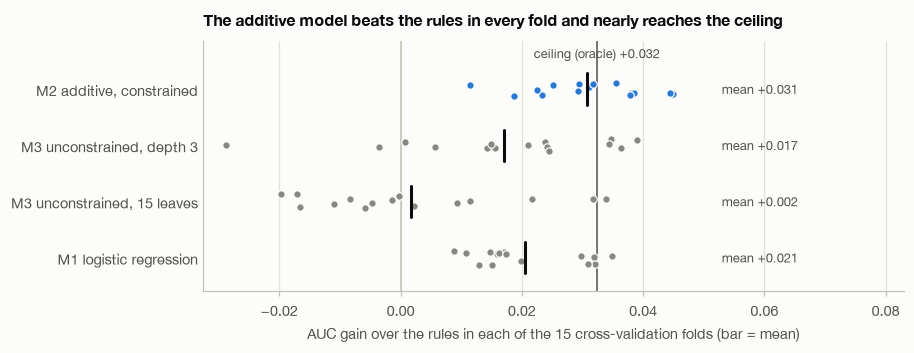

In [20]:
short_names = {
    "M1: logistic regression": "M1 logistic regression",
    "M3: unconstrained GBM, 15 leaves": "M3 unconstrained, 15 leaves",
    "M3: unconstrained GBM, depth 3": "M3 unconstrained, depth 3",
    "M2: additive GBM, direction-constrained": "M2 additive, constrained",
}
fold_gains = {
    name: candidate_cv[name].fold_metrics["ROC-AUC"].to_numpy() - rules_folds["ROC-AUC"].to_numpy() for name in short_names
}
ceiling_gain = float((oracle_folds["ROC-AUC"] - rules_folds["ROC-AUC"]).mean())
label_x = max(max(gain.max() for gain in fold_gains.values()), ceiling_gain) + 0.008
jitter = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8.4, 3.3))
for row, (name, gain) in enumerate(fold_gains.items()):
    color = plots.MODEL_COLOR if name.startswith("M2") else plots.RULES_COLOR
    ax.scatter(gain, row + jitter.uniform(-0.13, 0.13, len(gain)), s=24, color=color, edgecolor=plots.SURFACE,
               linewidth=0.8, zorder=3)
    ax.plot([gain.mean()] * 2, [row - 0.28, row + 0.28], color=plots.INK, linewidth=2, zorder=4)
    ax.text(label_x, row, f"mean {gain.mean():+.3f}", va="center", fontsize=8.5, color=plots.INK_SECONDARY)
ax.axvline(0, color=plots.AXIS, linewidth=1, zorder=1)
ax.axvline(ceiling_gain, color=plots.INK_SECONDARY, linewidth=1, zorder=1)
ax.text(ceiling_gain, len(fold_gains) - 0.45, f"ceiling (oracle) {ceiling_gain:+.3f}", ha="center", fontsize=8.5,
        color=plots.INK_SECONDARY)
ax.set_yticks(range(len(fold_gains)), list(short_names.values()))
ax.tick_params(axis="y", length=0)
ax.set_xlim(right=label_x + 0.03)
ax.set_ylim(-0.6, len(fold_gains) - 0.15)
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC gain over the rules in each of the 15 cross-validation folds (bar = mean)")
ax.set_title("The additive model beats the rules in every fold and nearly reaches the ceiling")
fig.tight_layout()
plots.save(fig, "fig5_model_comparison")
plt.show()

- **M2 is best.** AUC 0.731 against 0.701 for the rules on these folds, better in all 15 folds, and
  the lowest log-loss (0.535). It captures about 95% of the gain the oracle says is possible.
- **M1 (logistic regression)** also beats the rules (0.721), but its log-loss is more than one
  standard error worse than M2's: straight-line effects can't represent the steps in section 2.2.
- **M3 (unconstrained boosting) does worse than M2**, and the larger version barely beats the rules
  (better in only 6 of 15 folds). With 1,377 loans, the freedom to fit interactions mostly fits
  noise, and nothing suggests the risk drivers interact.
- So the constraints that make M2 interpretable also make it more accurate. There is no
  accuracy-versus-explainability trade-off to make here.

### 4.2 Tuning the additive model

A small grid over the learning rate, the number of leaves per tree and the minimum loans per leaf
(12 combinations), scored on the same folds. Under the selection rule, "simpler" means fewer leaves,
then more loans per leaf.

In [21]:
grid = [
    {"learning_rate": rate, "max_leaf_nodes": leaves, "min_samples_leaf": per_leaf}
    for rate in (0.05, 0.1) for leaves in (4, 8, 16) for per_leaf in (20, 50)
]


def setting_name(setting: dict) -> str:
    return (f"learning rate {setting['learning_rate']}, {setting['max_leaf_nodes']} leaves, "
            f"min {setting['min_samples_leaf']} per leaf")


grid_cv = {setting_name(s): cross_validate(partial(make_additive_gbm, **s), dev(core_tree), y_dev, splits) for s in grid}
grid_summary = summarize({name: result.fold_metrics for name, result in grid_cv.items()})
simplest_first = [setting_name(s) for s in sorted(
    grid, key=lambda s: (s["max_leaf_nodes"], -s["min_samples_leaf"], grid_summary.loc[setting_name(s), "log-loss"]))]
chosen_setting = one_se_choice(grid_summary, simplest_first)
display(grid_summary.sort_values("log-loss").round(4))
save_table(grid_summary, "models_grid")
print("Chosen:", chosen_setting)
assert chosen_setting == setting_name(ADDITIVE_GBM_PARAMS), "update ADDITIVE_GBM_PARAMS in loan_risk/modeling.py"

,ROC-AUC,ROC-AUC sd,PR-AUC,log-loss,log-loss se,Brier
"learning rate 0.05, 16 leaves, min 20 per leaf",0.7315,0.0248,0.5397,0.5341,0.0045,0.1788
"learning rate 0.05, 8 leaves, min 20 per leaf",0.7315,0.0248,0.5397,0.5341,0.0045,0.1788
"learning rate 0.05, 4 leaves, min 50 per leaf",0.7317,0.0242,0.5414,0.5341,0.0043,0.1788
"learning rate 0.05, 8 leaves, min 50 per leaf",0.7316,0.0244,0.5422,0.5343,0.0043,0.1788
"learning rate 0.05, 16 leaves, min 50 per leaf",0.7316,0.0244,0.5422,0.5343,0.0043,0.1788
"learning rate 0.05, 4 leaves, min 20 per leaf",0.7312,0.0245,0.5399,0.5343,0.0045,0.1789
"learning rate 0.1, 8 leaves, min 20 per leaf",0.7312,0.0249,0.5391,0.5344,0.0047,0.1790
"learning rate 0.1, 16 leaves, min 20 per leaf",0.7312,0.0249,0.5391,0.5344,0.0047,0.1790
"learning rate 0.1, 4 leaves, min 50 per leaf",0.7316,0.0246,0.5404,0.5345,0.0045,0.1789
"learning rate 0.1, 8 leaves, min 50 per leaf",0.7319,0.0242,0.5416,0.5345,0.0046,0.1789


Chosen: learning rate 0.05, 4 leaves, min 50 per leaf


Every setting lands within 0.0007 log-loss of the others. The model is insensitive to tuning, which
is reassuring: its accuracy comes from its structure, not from a lucky setting. The rule picks the
simplest one, which also ties for the best log-loss: learning rate 0.05, 4 leaves, at least 50 loans
per leaf. That is the production model from here on.

### 4.3 Which features earn their place?

Each candidate column is added to the core five, one at a time. Loan ÷ income is also recomputed
using documented income or bank deposits instead of stated income.

In [22]:
feature_sets = {"Core five (selected)": core_tree}
for extra in CANDIDATE_FEATURES:
    feature_sets[f"+ {FEATURE_LABELS[extra].lower()}"] = tree_matrix(features, PRODUCTION_VARIANT, (extra,))
for name, alternative in loan_to_income_alternatives(resolved).items():
    if name != "stated income":
        feature_sets[f"loan / income using {name}"] = core_tree.assign(loan_to_income=alternative.to_numpy())
feature_summary = summarize(
    {name: cross_validate(make_production_model, dev(X), y_dev, splits).fold_metrics for name, X in feature_sets.items()}
)
display(feature_summary.round(4))
save_table(feature_summary, "models_feature_ablation")

,ROC-AUC,ROC-AUC sd,PR-AUC,log-loss,log-loss se,Brier
Core five (selected),0.7317,0.0242,0.5414,0.5341,0.0043,0.1788
+ consistent deposits,0.7321,0.0244,0.5421,0.5341,0.0042,0.1787
+ documents submitted,0.7340,0.0246,0.5426,0.5330,0.0045,0.1785
+ stated monthly income ($),0.7279,0.0246,0.5357,0.5386,0.0045,0.1804
+ loan amount ($),0.7300,0.0237,0.5402,0.5354,0.0042,0.1792
+ documented / stated income,0.7317,0.0241,0.5414,0.5343,0.0043,0.1788
loan / income using documented income (stated if missing),0.7244,0.0264,0.5252,0.5412,0.0045,0.1814
loan / income using bank deposits,0.7289,0.0272,0.5318,0.5376,0.0046,0.1801


- **No extra column improves log-loss by more than its standard error**, so under the selection rule
  none is added. The document count comes closest, but its only real signal is "zero documents",
  which income verification already captures (one and two documents default at 25% and 28%).
  Adding raw stated income makes the model worse.
- **Stated income gives the best loan ÷ income.** The bank-deposit version costs a little (log-loss
  +0.0035, within one standard error) but is harder for applicants to game, which is worth weighing
  in production (section 8).

### 4.4 Does employment status add accuracy?

In [23]:
variant_cv = {v: cross_validate(make_production_model, dev(tree_matrix(features, v)), y_dev, splits) for v in EMPLOYMENT_VARIANTS}
variant_summary = summarize(
    {f"{v}: {VARIANT_DESCRIPTIONS[v]}": result.fold_metrics for v, result in variant_cv.items()},
    reference_auc=rules_folds["ROC-AUC"],
)
display(variant_summary.round(4))
save_table(variant_summary, "models_employment_variants")

,ROC-AUC,ROC-AUC sd,PR-AUC,log-loss,log-loss se,Brier,AUC gain vs rules,folds better than rules
V1: employment status (3 groups),0.7303,0.0242,0.5407,0.5348,0.0043,0.1790,0.0297,15/15
V2: unemployed flag only,0.7314,0.0245,0.5403,0.5343,0.0044,0.1788,0.0309,15/15
V3: no employment information,0.7317,0.0242,0.5414,0.5341,0.0043,0.1788,0.0312,15/15


All three variants are equally accurate: log-loss within 0.0007 of each other, with the version
without employment nominally the best. Once income verification, affordability and bank behaviour
are known, employment status adds no predictive value. So whether to use it is entirely a fairness
question (section 7). The working model leaves it out.

### 4.5 Are the probabilities calibrated?

A calibrated model's 20% means 20%: among applicants given 20%, about one in five defaults. That
matters when probabilities drive thresholds, pricing or expected-loss estimates.

,ROC-AUC,ROC-AUC sd,PR-AUC,log-loss,log-loss se,Brier
Selected model,0.7317,0.0242,0.5414,0.5341,0.0043,0.1788
Selected model + Platt scaling,0.7317,0.0242,0.5414,0.5345,0.0044,0.1789


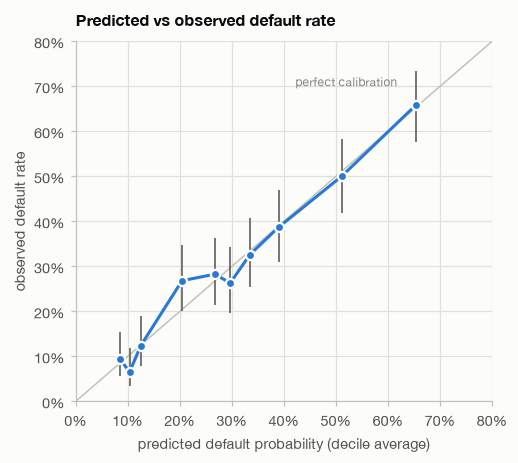

,n,predicted (%),rate (%),ci_low (%),ci_high (%),predicted inside 95% CI
0,138,8.5,9.4,5.6,15.5,True
1,138,10.4,6.5,3.5,11.9,True
2,137,12.5,12.4,7.9,19.0,True
3,138,20.4,26.8,20.1,34.8,True
4,138,26.8,28.3,21.4,36.3,True
5,137,29.7,26.3,19.6,34.2,True
6,138,33.5,32.6,25.4,40.8,True
7,137,39.0,38.7,30.9,47.0,True
8,138,51.1,50.0,41.8,58.2,True
9,138,65.5,65.9,57.7,73.3,True


Average predicted probability 29.7% vs observed default rate 29.7%


In [24]:
selected_cv = variant_cv[PRODUCTION_VARIANT]
platt_cv = cross_validate(make_platt_calibrated, dev(core_tree), y_dev, splits)
display(summarize({"Selected model": selected_cv.fold_metrics,
                   "Selected model + Platt scaling": platt_cv.fold_metrics}).round(4))

oof = selected_cv.mean_oof
decile = pd.qcut(oof, 10, labels=False)
calibration = rate_table(y_dev, decile, list(range(10)))
calibration["predicted"] = pd.Series(oof).groupby(decile).mean()
calibration["predicted inside 95% CI"] = calibration["predicted"].between(calibration["ci_low"], calibration["ci_high"])

fig, ax = plt.subplots(figsize=(4.8, 4.3))
ax.plot([0, 0.8], [0, 0.8], color=plots.AXIS, linewidth=1, zorder=1)
ax.text(0.52, 0.70, "perfect calibration", fontsize=8, color=plots.MUTED, ha="center")
ax.errorbar(calibration["predicted"], calibration["rate"],
            yerr=[calibration["rate"] - calibration["ci_low"], calibration["ci_high"] - calibration["rate"]],
            fmt="none", ecolor=plots.INK_SECONDARY, elinewidth=1, zorder=2)
ax.plot(calibration["predicted"], calibration["rate"], color=plots.BLUE, marker="o", markersize=6,
        markeredgecolor=plots.SURFACE, markeredgewidth=1.5, zorder=3)
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 0.8)
plots.percent_axis(ax)
plots.percent_axis(ax, "x")
ax.grid(axis="x", visible=True)
ax.set_xlabel("predicted default probability (decile average)")
ax.set_ylabel("observed default rate")
ax.set_title("Predicted vs observed default rate")
fig.tight_layout()
plots.save(fig, "fig6_calibration")
plt.show()
display(format_rates(calibration[["n", "predicted", "rate", "ci_low", "ci_high", "predicted inside 95% CI"]],
                     columns=("predicted", "rate", "ci_low", "ci_high")))
print(f"Average predicted probability {oof.mean():.1%} vs observed default rate {y_dev.mean():.1%}")

Calibration is good: 29.7% predicted on average against 29.7% observed, and in every decile the
predicted rate falls inside the 95% confidence interval of the observed rate. Platt scaling
(refitting a sigmoid on top) doesn't improve log-loss, so the model is used as is. That also keeps
its explanations simple, because every contribution is in the model's own log-odds.

### 4.6 The choice

The production model is **M2: additive gradient boosting with direction constraints** (learning
rate 0.05, 4 leaves, at least 50 loans per leaf) on the five core features, without employment
status and without recalibration.
- **It wins on the rule set in advance:** lowest cross-validated log-loss, better than the rules in
  all 15 folds, about 95% of the possible AUC gain.
- **It is interpretable by design:** every prediction is a sum of five per-feature contributions,
  and each feature's effect points the sensible way (section 6 shows them).
- **The choice isn't fragile:** every tuning setting performs the same, no extra column helps, and
  employment status adds nothing.

Section 5 trains it on all 1,377 development loans and scores the untouched test set for the first
time.

## 5. The model against the baseline

The production model is trained once on all 1,377 development loans and then scores the 459 test
loans it has never seen. It is compared with the rules as they are, the patched rules from section
3.5 (the stronger baseline) and the oracle ceiling.

### 5.1 Ranking quality on the test set

In [25]:
final_model = make_production_model(core_tree.columns).fit(dev(core_tree), y_dev)
p_test = final_model.predict_proba(core_tree.iloc[test_rows])[:, 1]
y_test = y[test_rows]
patched_risk = -adjusted_rule_score(resolved, self_employed_points=100, ignore_deposit_consistency=True).to_numpy()
test_scores = {
    "Rules as they are": rule_risk[test_rows],
    "Patched rules (patch 2)": patched_risk[test_rows],
    "Model": p_test,
    "Oracle (ceiling, diagnostic only)": oracle_p[test_rows],
}
rows = {}
for name, score in test_scores.items():
    rows[name] = ranking_metrics(y_test, score)
    if name.startswith(("Model", "Oracle")):
        rows[name] |= probability_metrics(y_test, score)
test_ranking = pd.DataFrame.from_dict(rows, orient="index")
display(test_ranking.round(4))
save_table(test_ranking, "test_ranking")

test_gains = pd.DataFrame.from_dict(
    {f"Model vs {name.lower()}": paired_bootstrap(y_test, test_scores[name], p_test, roc_auc_score)
     for name in ["Rules as they are", "Patched rules (patch 2)"]},
    orient="index",
)
display(test_gains.round(4))
save_table(test_gains, "test_auc_gains")
print(f"Test set: the model predicts {p_test.mean():.1%} default on average; {y_test.mean():.1%} actually defaulted")

,ROC-AUC,PR-AUC,log-loss,Brier
Rules as they are,0.7253,0.5494,NaN,NaN
Patched rules (patch 2),0.7415,0.5532,NaN,NaN
Model,0.7614,0.5504,0.5183,0.1721
"Oracle (ceiling, diagnostic only)",0.7662,0.5368,0.5115,0.1692


,difference,ci_low,ci_high,share of resamples where B is better
Model vs rules as they are,0.0361,-0.0017,0.0727,0.9695
Model vs patched rules (patch 2),0.0199,-0.0129,0.0530,0.8750


Test set: the model predicts 29.8% default on average; 29.6% actually defaulted


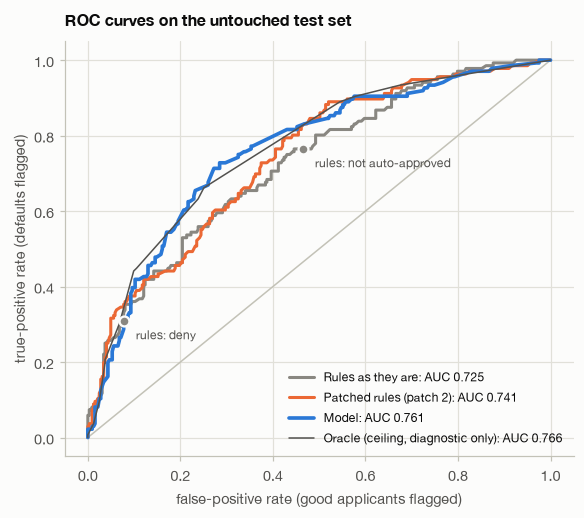

In [26]:
test_rule_tiers = rule_tiers(resolved)[test_rows]
roc_styles = {
    "Rules as they are": (plots.RULES_COLOR, 2.0),
    "Patched rules (patch 2)": (plots.ORANGE, 2.0),
    "Model": (plots.MODEL_COLOR, 2.4),
    "Oracle (ceiling, diagnostic only)": (plots.INK_SECONDARY, 1.0),
}
fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.plot([0, 1], [0, 1], color=plots.AXIS, linewidth=1)
for name, score in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    color, width = roc_styles[name]
    ax.plot(fpr, tpr, color=color, linewidth=width, label=f"{name}: AUC {roc_auc_score(y_test, score):.3f}")
for flagged, label in [(("deny",), "rules: deny"), (("deny", "review"), "rules: not auto-approved")]:
    point = binary_metrics(y_test, np.isin(test_rule_tiers, flagged))
    ax.scatter(point["FPR"], point["recall"], s=42, color=plots.RULES_COLOR, edgecolor=plots.SURFACE, linewidth=1.5,
               zorder=5)
    ax.annotate(label, (point["FPR"], point["recall"]), xytext=(8, -12), textcoords="offset points", fontsize=8,
                color=plots.INK_SECONDARY)
ax.set_xlabel("false-positive rate (good applicants flagged)")
ax.set_ylabel("true-positive rate (defaults flagged)")
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("ROC curves on the untouched test set")
fig.tight_layout()
plots.save(fig, "fig7_roc_test")
plt.show()

- On loans it has never seen, the model reaches **AUC 0.761**, against 0.725 for the rules and 0.742
  for the patched rules, close to the oracle's 0.766.
- The gain over the rules is +0.036 (95% CI -0.002 to +0.073; 97% of bootstrap resamples favour the
  model), and over the patched rules +0.020 (CI -0.013 to +0.053). A 459-loan test set can't pin
  down differences this small, which is why section 5.3 adds a larger check.
- Every system scores higher here than in cross-validation, the oracle included (0.766 vs 0.733),
  so this test set is simply an easier sample. The gaps between systems are what matter.
- The probabilities stay calibrated on new data: 29.8% predicted on average, 29.6% observed.
- PR-AUC is about the same for every system here (0.54-0.55), the oracle included. With only 136
  defaults it is too noisy to separate them.

### 5.2 Decisions on the test set, at today's volumes

Each system auto-approves as many test applicants as the rules did and denies as many, so the
comparison is purely about who lands where. The confusion matrices use the two conventions from
section 3.3.

In [27]:
n_test_approve, n_test_deny = int((test_rule_tiers == "approve").sum()), int((test_rule_tiers == "deny").sum())
test_tiers = {"Rules as they are": test_rule_tiers}
for name in ["Patched rules (patch 2)", "Model", "Oracle (ceiling, diagnostic only)"]:
    test_tiers[name] = matched_tiers(test_scores[name], n_test_approve, n_test_deny)
display(pd.concat({name: tier_table(y_test, tiers)[["applicants", "repaid", "defaulted", "default rate"]]
                   for name, tiers in test_tiers.items()}).round(3))
test_conventions = pd.concat({name: convention_metrics(y_test, tiers) for name, tiers in test_tiers.items()})
display(test_conventions.round(3))
save_table(test_conventions, "test_conventions")
display(pd.concat(
    {(name, convention.split(":")[0]): confusion_table(y_test, np.isin(test_tiers[name], flagged))
     for name in ["Rules as they are", "Model"] for convention, flagged in CONVENTIONS.items()},
    axis=1,
))

applicants  repaid  defaulted  \
Rules as they are                 approve         205     173         32   
                                  review          187     125         62   
                                  deny             67      25         42   
Patched rules (patch 2)           approve         205     178         27   
                                  review          187     124         63   
                                  deny             67      21         46   
Model                             approve         205     180         25   
                                  review          187     117         70   
                                  deny             67      26         41   
Oracle (ceiling, diagnostic only) approve         205     180         25   
                                  review          187     121         66   
                                  deny             67      22         45   

                                           default rate  
Rules as they are                 approve         0.156  
                                  review          0.332  
                                  deny            0.627  
Patched rules (patch 2)           approve         0.132  
                                  review          0.337  
                                  deny            0.687  
Model                             approve         0.122  
                                  review          0.374  
                                  deny            0.612  
Oracle (ceiling, diagnostic only) approve         0.122  
                                  review          0.353  
                                  deny            0.672

TP  \
Rules as they are                 A: only deny = predicted default           42   
                                  B: not auto-approved = predicted default  104   
Patched rules (patch 2)           A: only deny = predicted default           46   
                                  B: not auto-approved = predicted default  109   
Model                             A: only deny = predicted default           41   
                                  B: not auto-approved = predicted default  111   
Oracle (ceiling, diagnostic only) A: only deny = predicted default           45   
                                  B: not auto-approved = predicted default  111   

                                                                             FP  \
Rules as they are                 A: only deny = predicted default           25   
                                  B: not auto-approved = predicted default  150   
Patched rules (patch 2)           A: only deny = predicted default           21   
                                  B: not auto-approved = predicted default  145   
Model                             A: only deny = predicted default           26   
                                  B: not auto-approved = predicted default  143   
Oracle (ceiling, diagnostic only) A: only deny = predicted default           22   
                                  B: not auto-approved = predicted default  143   

                                                                            FN  \
Rules as they are                 A: only deny = predicted default          94   
                                  B: not auto-approved = predicted default  32   
Patched rules (patch 2)           A: only deny = predicted default          90   
                                  B: not auto-approved = predicted default  27   
Model                             A: only deny = predicted default          95   
                                  B: not auto-approved = predicted default  25   
Oracle (ceiling, diagnostic only) A: only deny = predicted default          91   
                                  B: not auto-approved = predicted default  25   

                                                                             TN  \
Rules as they are                 A: only deny = predicted default          298   
                                  B: not auto-approved = predicted default  173   
Patched rules (patch 2)           A: only deny = predicted default          302   
                                  B: not auto-approved = predicted default  178   
Model                             A: only deny = predicted default          297   
                                  B: not auto-approved = predicted default  180   
Oracle (ceiling, diagnostic only) A: only deny = predicted default          301   
                                  B: not auto-approved = predicted default  180   

                                                                            precision  \
Rules as they are                 A: only deny = predicted default              0.627   
                                  B: not auto-approved = predicted default      0.409   
Patched rules (patch 2)           A: only deny = predicted default              0.687   
                                  B: not auto-approved = predicted default      0.429   
Model                             A: only deny = predicted default              0.612   
                                  B: not auto-approved = predicted default      0.437   
Oracle (ceiling, diagnostic only) A: only deny = predicted default              0.672   
                                  B: not auto-approved = predicted default      0.437   

                                                                            recall  \
Rules as they are                 A: only deny = predicted default           0.309   
                                  B: not auto-approved = predicted default   0.765   
Patched rules (patch 2)           

Rules as they are                                    \
                          A                                 B   
            predicted repay predicted default predicted repay   
actual                                                          
repaid                  298                25             173   
defaulted                94                42              32   

                                      Model                                    \
                                          A                                 B   
          predicted default predicted repay predicted default predicted repay   
actual                                                                          
repaid                  150             297                26             180   
defaulted               104              95                41              25   

                             
                             
          predicted default  
actual                       
repaid                  143  
defaulted               111

On the test set the model's gain shows up at the approval cutoff: 25 defaults slip through
auto-approval against the rules' 32 (the oracle also lets through 25), so under convention B its
false-negative rate is 18.4% against 23.5%. Its deny tier performs like the rules' (41 vs 42 defaults
caught). With only 67 denials per system those counts move by several loans from sample to sample,
so section 5.4 uses all 1,836 loans for stable estimates.

### 5.3 Robustness: every loan scored out-of-fold

459 test loans give wide confidence intervals, and tier counts that small are noisy. So the
production pipeline also runs through 5-fold cross-validation repeated 5 times on all 1,836
resolved loans. Every loan is scored by models that never saw it; those scores, averaged over the 5
repeats, drive the portfolio and fairness analyses that follow. The pipeline is fixed, so nothing
is being selected here.

In [28]:
portfolio_splits = cv_splits(y, n_splits=5, n_repeats=5)
portfolio_cv = cross_validate(make_production_model, core_tree, y, portfolio_splits)
oof_all = portfolio_cv.mean_oof
rows = {}
for name, score in {"Model vs rules as they are": rule_risk, "Model vs patched rules": patched_risk}.items():
    gain = np.array([roc_auc_score(y[test], portfolio_cv.oof[repeat, test]) - roc_auc_score(y[test], score[test])
                     for repeat, _, test in portfolio_splits])
    rows[name] = {"mean AUC gain": gain.mean(), "smallest": gain.min(), "largest": gain.max(),
                  "folds where the model is better": f"{(gain > 0).sum()}/{len(gain)}"}
robustness = pd.DataFrame.from_dict(rows, orient="index")
display(robustness.round(4))
save_table(robustness, "robustness_auc_gains")
print("Out-of-fold AUC over all 1,836 loans: " + ", ".join(
    f"{name} {roc_auc_score(y, score):.3f}"
    for name, score in {"model": oof_all, "rules": rule_risk, "patched rules": patched_risk, "oracle": oracle_p}.items()))

,mean AUC gain,smallest,largest,folds where the model is better
Model vs rules as they are,0.0324,-0.0015,0.0622,24/25
Model vs patched rules,0.0214,-0.0062,0.0476,22/25


Out-of-fold AUC over all 1,836 loans: model 0.738, rules 0.706, patched rules 0.718, oracle 0.741


Across 25 folds the model beats the rules in 24 (mean +0.032) and the patched rules in 22 (mean
+0.021). Over all 1,836 loans its out-of-fold AUC is 0.738, against 0.706 for the rules, 0.718 for
the patched rules and 0.741 for the oracle. The test-set result is not a fluke of one split.

### 5.4 What would change if we deployed tomorrow?

All 1,836 resolved loans, scored out-of-fold, at today's volumes: 851 auto-approved, 720 sent to
review, 265 denied.

In [29]:
portfolio_tiers = {
    "Rules as they are": rule_decisions,
    "Patched rules (patch 2)": matched_tiers(patched_risk, n_approve, n_deny),
    "Model": matched_tiers(oof_all, n_approve, n_deny),
    "Oracle (ceiling, diagnostic only)": matched_tiers(oracle_p, n_approve, n_deny),
}
loan_amounts = resolved["loan_amount"].to_numpy()
rows = {}
for name, tiers in portfolio_tiers.items():
    approved, denied = tiers == "approve", tiers == "deny"
    rows[name] = {
        "defaults auto-approved": int(y[approved].sum()),
        "defaults denied": int(y[denied].sum()),
        "good applicants denied": int((1 - y)[denied].sum()),
        "default rate among approved": y[approved].mean(),
        **dollars_approved(y, tiers, loan_amounts),
        "self-employed approval ratio": approval_ratio(tiers, "self_employed"),
    }
portfolio = pd.DataFrame.from_dict(rows, orient="index")
display(portfolio.round(3))
save_table(portfolio, "portfolio_same_volume")
counts = ["defaults auto-approved", "defaults denied", "good applicants denied"]
display((portfolio[counts] * 1000 / len(y)).round(1).add_suffix(" per 1,000 applications"))
display(swap_sets(y, rule_decisions, portfolio_tiers["Model"], resolved["employment_status"],
                  order=EMPLOYMENT_GROUPS).rename(columns=GROUP_LABELS).round(3))

,defaults auto-approved,defaults denied,good applicants denied,default rate among approved,$ lent to defaulters,$ lent to repayers,self-employed approval ratio
Rules as they are,141,143,122,0.166,193500.0,722500.0,0.596
Patched rules (patch 2),124,155,110,0.146,159600.0,738600.0,0.878
Model,128,167,98,0.150,146100.0,688500.0,0.891
"Oracle (ceiling, diagnostic only)",123,170,95,0.145,190100.0,767800.0,0.929


,"defaults auto-approved per 1,000 applications","defaults denied per 1,000 applications","good applicants denied per 1,000 applications"
Rules as they are,76.8,77.9,66.4
Patched rules (patch 2),67.5,84.4,59.9
Model,69.7,91.0,53.4
"Oracle (ceiling, diagnostic only)",67.0,92.6,51.7


,applicants,default rate,Employed,Self-employed,Unemployed
newly approved,162,0.284,68,69,25
no longer approved,162,0.364,153,9,0


In [30]:
for name in ["Rules as they are", "Patched rules (patch 2)"]:
    saved = portfolio.loc[name, "$ lent to defaulters"] - portfolio.loc["Model", "$ lent to defaulters"]
    forgone = portfolio.loc[name, "$ lent to repayers"] - portfolio.loc["Model", "$ lent to repayers"]
    if forgone <= 0 or saved / forgone >= 1:
        verdict = "at any realistic margin" + (f" (break-even: {saved / forgone:.0%} of principal)" if forgone > 0 else "")
    else:
        verdict = f"if repaid loans earn less than {saved / forgone:.0%} of principal"
    print(f"Model vs {name.lower()}: ${saved:,.0f} less lent to defaulters, ${forgone:,.0f} less lent to repayers. "
          f"Assuming a default loses the whole loan, the model comes out ahead {verdict}.")

rule_default_rate = y[rule_decisions == "approve"].mean()
k = approvals_at_predicted_rate(oof_all, rule_default_rate)
growth = np.argsort(oof_all, kind="mergesort")[:k]
print(f"\nToday the rules approve {n_approve} applicants ({n_approve / len(y):.0%}) with a {rule_default_rate:.1%} default rate.")
print(f"Setting the model's cutoff so its predicted default rate among approved is {rule_default_rate:.1%} approves "
      f"{k} ({k / len(y):.0%}): {k - n_approve} more. Their actual default rate: {y[growth].mean():.1%}.")

Model vs rules as they are: $47,400 less lent to defaulters, $34,000 less lent to repayers. Assuming a default loses the whole loan, the model comes out ahead at any realistic margin (break-even: 139% of principal).
Model vs patched rules (patch 2): $13,500 less lent to defaulters, $50,100 less lent to repayers. Assuming a default loses the whole loan, the model comes out ahead if repaid loans earn less than 27% of principal.

Today the rules approve 851 applicants (46%) with a 16.6% default rate.
Setting the model's cutoff so its predicted default rate among approved is 16.6% approves 991 (54%): 140 more. Their actual default rate: 16.6%.


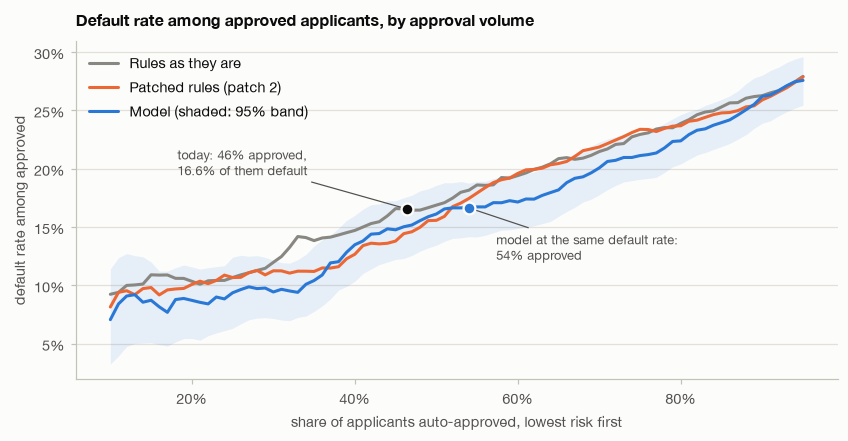

In [31]:
shares = np.arange(0.10, 0.951, 0.01)
band_low, band_high = bootstrap_strategy_band(y, oof_all, shares)
fig, ax = plt.subplots(figsize=(7.8, 4.1))
ax.fill_between(shares, band_low, band_high, color=plots.MODEL_COLOR, alpha=0.10, linewidth=0)
for name, score, color in [("Rules as they are", rule_risk, plots.RULES_COLOR),
                           ("Patched rules (patch 2)", patched_risk, plots.ORANGE),
                           ("Model (shaded: 95% band)", oof_all, plots.MODEL_COLOR)]:
    ax.plot(shares, strategy_curve(y, score, shares), color=color, linewidth=2, label=name)
today = n_approve / len(y)
ax.scatter([today], [rule_default_rate], s=60, color=plots.INK, edgecolor=plots.SURFACE, linewidth=1.5, zorder=5)
ax.annotate(f"today: {today:.0%} approved,\n{rule_default_rate:.1%} of them default", (today, rule_default_rate),
            xytext=(-150, 22), textcoords="offset points", fontsize=8.5, color=plots.INK_SECONDARY,
            arrowprops={"arrowstyle": "-", "color": plots.INK_SECONDARY, "linewidth": 0.8})
ax.scatter([k / len(y)], [y[growth].mean()], s=60, color=plots.MODEL_COLOR, edgecolor=plots.SURFACE, linewidth=1.5,
           zorder=5)
ax.annotate(f"model at the same default rate:\n{k / len(y):.0%} approved", (k / len(y), y[growth].mean()),
            xytext=(18, -34), textcoords="offset points", fontsize=8.5, color=plots.INK_SECONDARY,
            arrowprops={"arrowstyle": "-", "color": plots.INK_SECONDARY, "linewidth": 0.8})
ax.set_xlabel("share of applicants auto-approved, lowest risk first")
ax.set_ylabel("default rate among approved")
plots.percent_axis(ax)
plots.percent_axis(ax, "x")
ax.legend(loc="upper left")
ax.set_title("Default rate among approved applicants, by approval volume")
fig.tight_layout()
plots.save(fig, "fig8_strategy_curve")
plt.show()

**At today's volumes**, compared with the rules, the model:
- lets 13 fewer defaults through auto-approval (141 to 128: 7 fewer per 1,000 applications);
- catches 24 more defaults in the deny tier (143 to 167: 13 more per 1,000);
- wrongly denies 24 fewer good applicants (122 to 98: 13 fewer per 1,000).

Both kinds of error fall at once, so at today's volumes there is no trade-off to weigh.

**Who changes.** The 162 applicants the model newly approves default at 28%, and include 69
self-employed and 25 unemployed applicants. The 162 it stops approving default at 36% and are almost
all employed (153). The self-employed approval ratio rises from 0.60 to 0.89.

**Money.** $47,400 less is lent to applicants who default (a 24% cut) and $34,000 less to applicants
who repay, because the model favours loans that are small relative to income. Assuming a default
loses the whole loan, the model beats today's rules at any realistic margin, and beats the patched
rules if repaid loans earn less than about 27% of principal.

**Or grow instead.** Setting the model's cutoff so that its *predicted* default rate among approved
matches today's 16.6% would approve 991 applicants (54%) instead of 851 (46%), 140 more, and their
*actual* default rate is 16.6%, exactly as predicted. The curve shows the full menu. The model keeps
the default rate below today's rules at almost every approval volume. The patched rules match it
around today's volume (within the model's uncertainty band), but fall behind once more than about
55% of applicants are approved.

### 5.5 Verdict

- **Against today's rules, the model is better on every measure:** AUC +0.032 (better in 24 of 25
  folds; +0.036 on the test set), fewer defaults approved, more caught, fewer good applicants denied,
  a quarter less money lent to defaulters, and self-employed applicants treated almost like employed
  ones. It reaches about 95% of the gain any model could achieve on this data.
- **Against the patched rules, the gain is smaller but consistent:** AUC +0.021 (better in 22 of 25
  folds). The two are level at today's approval cutoff (128 vs 124 defaults let through), and the
  model catches 12 more defaults while wrongly denying 12 fewer good applicants in the deny tier. It
  also produces calibrated probabilities, which the rules can't. Those are what make "approve 140
  more at the same default rate" possible, and they can be re-calibrated when conditions change
  (section 8).
- **Recommendation:** replace the rules with the model, starting in shadow mode. If something has to
  ship before the model is approved, the two-line rules patch delivers most of the fairness gain and
  part of the accuracy gain immediately.